# Exercício 1 — Valores Ausentes
## Melbourne Housing Snapshot

### IMPORTAÇÕES

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import missingno as msno

### CARREGAMENTO DOS DADOS E DIAGNÓSTICO INICIAL

In [16]:
df = pd.read_csv("../data/melb_data.csv")

print(df.head())
print(df.shape)

       Suburb           Address  Rooms Type      Price Method SellerG  \
0  Abbotsford      85 Turner St      2    h  1480000.0      S  Biggin   
1  Abbotsford   25 Bloomburg St      2    h  1035000.0      S  Biggin   
2  Abbotsford      5 Charles St      3    h  1465000.0     SP  Biggin   
3  Abbotsford  40 Federation La      3    h   850000.0     PI  Biggin   
4  Abbotsford       55a Park St      4    h  1600000.0     VB  Nelson   

        Date  Distance  Postcode  ...  Bathroom  Car  Landsize  BuildingArea  \
0  3/12/2016       2.5    3067.0  ...       1.0  1.0     202.0           NaN   
1  4/02/2016       2.5    3067.0  ...       1.0  0.0     156.0          79.0   
2  4/03/2017       2.5    3067.0  ...       2.0  0.0     134.0         150.0   
3  4/03/2017       2.5    3067.0  ...       2.0  1.0      94.0           NaN   
4  4/06/2016       2.5    3067.0  ...       1.0  2.0     120.0         142.0   

   YearBuilt  CouncilArea Lattitude  Longtitude             Regionname  \
0     

In [ ]:
# Tipo de cada coluna
df.dtypes

Suburb            object
Address           object
Rooms              int64
Type              object
Price            float64
Method            object
SellerG           object
Date              object
Distance         float64
Postcode         float64
Bedroom2         float64
Bathroom         float64
Car              float64
Landsize         float64
BuildingArea     float64
YearBuilt        float64
CouncilArea       object
Lattitude        float64
Longtitude       float64
Regionname        object
Propertycount    float64
dtype: object

### RESUMO DE VALORES AUSENTES (QUANTIDADE E %)

In [ ]:
# Número de valores nulos em cada coluna
df.isnull().sum()

Suburb              0
Address             0
Rooms               0
Type                0
Price               0
Method              0
SellerG             0
Date                0
Distance            0
Postcode            0
Bedroom2            0
Bathroom            0
Car                62
Landsize            0
BuildingArea     6450
YearBuilt        5375
CouncilArea      1369
Lattitude           0
Longtitude          0
Regionname          0
Propertycount       0
dtype: int64

In [ ]:
# Percentual de valores nulos em cada coluna
(df.isnull().mean() * 100).sort_values(ascending=False)

BuildingArea     47.496318
YearBuilt        39.580265
CouncilArea      10.081001
Car               0.456554
Suburb            0.000000
Price             0.000000
Type              0.000000
Rooms             0.000000
Address           0.000000
Distance          0.000000
Method            0.000000
Date              0.000000
SellerG           0.000000
Bathroom          0.000000
Bedroom2          0.000000
Postcode          0.000000
Landsize          0.000000
Lattitude         0.000000
Longtitude        0.000000
Regionname        0.000000
Propertycount     0.000000
dtype: float64

### VISUALIZAÇÃO DO PADRÃO DE AUSÊNCIA

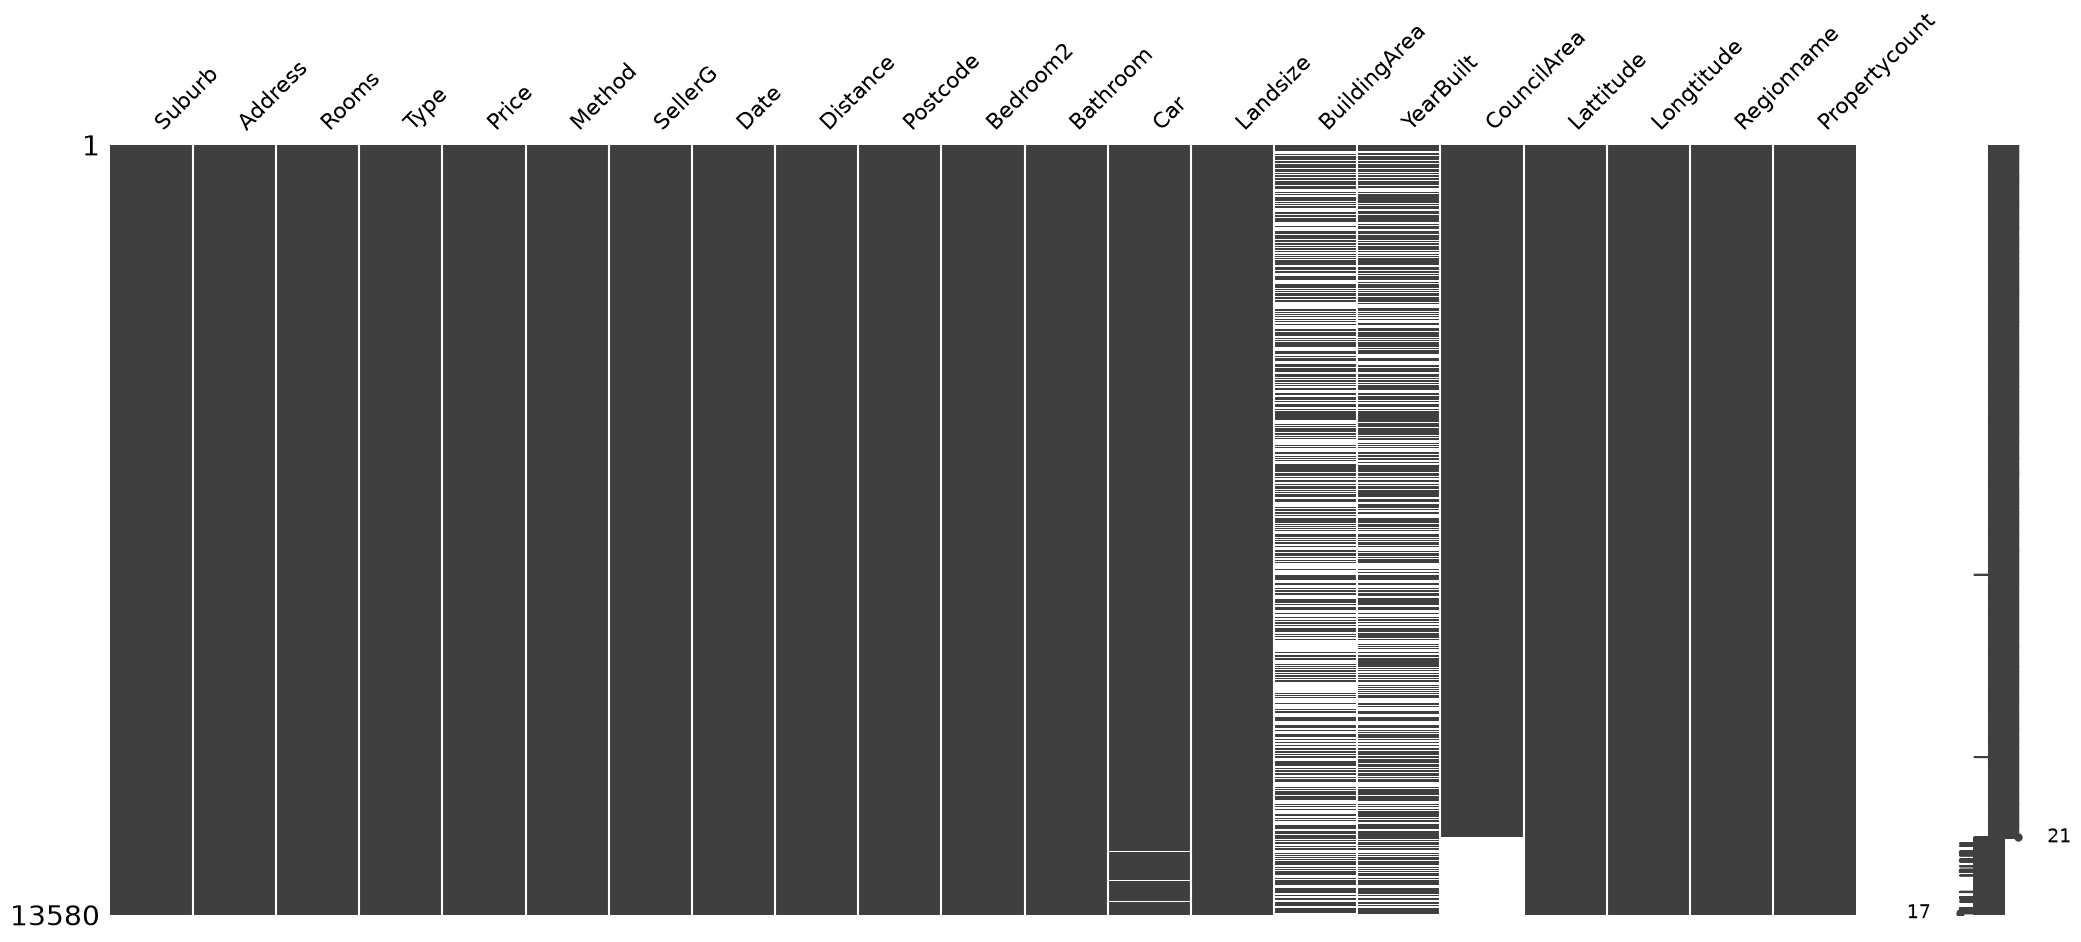

In [15]:
msno.matrix(df)
plt.show()

### ESTRATÉGIA 1 — REMOÇÃO

In [19]:
df_remocao = df.dropna().copy()
print("Valores ausentes restantes:", df_remocao.isnull().sum().sum())

Valores ausentes restantes: 0


### ESTRATÉGIA 2 — IMPUTAÇÃO

In [20]:
df_imputacao = df.copy()

# Colunas numéricas: preencher com a mediana
colunas_numericas = ["Car", "BuildingArea", "YearBuilt"]

for coluna in colunas_numericas:
    df_imputacao[coluna] = df_imputacao[coluna].fillna(
        df_imputacao[coluna].median()
    )

# Coluna categórica: preencher com a moda
moda_council = df_imputacao["CouncilArea"].mode()

if not moda_council.empty:
    df_imputacao["CouncilArea"] = df_imputacao["CouncilArea"].fillna(
        moda_council.iloc[0]
    )

print("Valores ausentes restantes:", df_remocao.isnull().sum().sum())

Valores ausentes restantes: 0


### COMPARAÇÃO ENTRE AS ESTRATÉGIAS

In [21]:
print("Dataset original:", df.shape)
print("Após remoção:", df_remocao.shape)
print("Após imputação:", df_imputacao.shape)

Dataset original: (13580, 21)
Após remoção: (6196, 21)
Após imputação: (13580, 21)


### RESPOSTAS ÀS PERGUNTAS DE REFLEXÃO

1. **Uma coluna com mais da metade dos valores ausentes deve ser imputada ou descartada?**

   Uma coluna com muitos valores ausentes não precisa ser descartada automaticamente. A decisão depende da importância da informação para a análise e da quantidade de dados que ainda está disponível. Se a coluna for pouco relevante, pode ser melhor removê-la. Porém, se for importante para o estudo, podemos tentar imputar os valores ou investigar por que estão ausentes.

2. **Para colunas como Price ou Landsize, média e mediana dariam valores parecidos? Qual seria mais segura, e por quê?**

   Não necessariamente. Essas colunas podem apresentar valores muito altos ou muito baixos em comparação com a maioria dos registros, o que influencia a média. A mediana costuma ser mais segura nesses casos, pois é menos afetada por valores extremos e representa melhor o centro dos dados quando a distribuição é assimétrica. Se os dados tiverem uma distribuição equilibrada e poucos valores extremos, a média e a mediana podem ser parecidas.

3. **Em que situação o fato de um valor estar ausente é, por si só, uma informação útil para a análise?**

   A ausência pode indicar alguma característica importante do registro. Por exemplo, se o ano de construção (`YearBuilt`) estiver ausente com maior frequência em imóveis antigos, isso pode revelar um padrão nos dados. Da mesma forma, se o preço estiver ausente em determinados tipos de imóveis, essa ausência pode estar relacionada à forma como os dados foram coletados. Nesses casos, vale analisar o padrão das ausências e até criar uma coluna indicadora para registrar quais valores estavam ausentes antes da imputação.

### DESAFIO

In [24]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

colunas_knn = ["Car", "BuildingArea", "YearBuilt"]
df_knn = df.copy()

scaler = StandardScaler()
X = df[colunas_knn]

# Padronizar as escalas
X_scaled = scaler.fit_transform(X)

# Imputar utilizando os 5 vizinhos mais próximos
knn = KNNImputer(n_neighbors=5)
X_imputado = knn.fit_transform(X_scaled)

# Retornar à escala original
X_original = scaler.inverse_transform(X_imputado)

df_knn[colunas_knn] = X_original

coluna = "BuildingArea"

comparacao = pd.DataFrame({
    "Original": df[coluna].agg(["mean", "median"]),
    "Mediana": df_imputacao[coluna].agg(["mean", "median"]),
    "KNN": df_knn[coluna].agg(["mean", "median"])
})

print(comparacao.round(2))

        Original  Mediana     KNN
mean      151.97   139.63  153.35
median    126.00   126.00  130.00


# Exercício 2 — Duplicatas
## Customer Transaction Dataset (KPMG)

### CARREGAMENTO DE DADOS

In [14]:
df = pd.read_excel("../data/KPMG_VI_New_raw_data_update_final.xlsx", sheet_name="Transactions", header=1)
df.head()

,transaction_id,product_id,customer_id,transaction_date,online_order,order_status,brand,product_line,product_class,product_size,list_price,standard_cost,product_first_sold_date
0,1,2,2950,2017-02-25,0.0,Approved,Solex,Standard,medium,medium,71.49,53.62,41245.0
1,2,3,3120,2017-05-21,1.0,Approved,Trek Bicycles,Standard,medium,large,2091.47,388.92,41701.0
2,3,37,402,2017-10-16,0.0,Approved,OHM Cycles,Standard,low,medium,1793.43,248.82,36361.0
3,4,88,3135,2017-08-31,0.0,Approved,Norco Bicycles,Standard,medium,medium,1198.46,381.10,36145.0
4,5,78,787,2017-10-01,1.0,Approved,Giant Bicycles,Standard,medium,large,1765.30,709.48,42226.0


### CONFERÊNCIA DO CABEÇALHO E DOS TIPOS

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   transaction_id           20000 non-null  int64         
 1   product_id               20000 non-null  int64         
 2   customer_id              20000 non-null  int64         
 3   transaction_date         20000 non-null  datetime64[ns]
 4   online_order             19640 non-null  float64       
 5   order_status             20000 non-null  object        
 6   brand                    19803 non-null  object        
 7   product_line             19803 non-null  object        
 8   product_class            19803 non-null  object        
 9   product_size             19803 non-null  object        
 10  list_price               20000 non-null  float64       
 11  standard_cost            19803 non-null  float64       
 12  product_first_sold_date  19803 n

In [15]:
df.dtypes

transaction_id                      int64
product_id                          int64
customer_id                         int64
transaction_date           datetime64[ns]
online_order                      float64
order_status                       object
brand                              object
product_line                       object
product_class                      object
product_size                       object
list_price                        float64
standard_cost                     float64
product_first_sold_date           float64
dtype: object

### DUPLICATAS EXATAS

In [20]:
df.duplicated().sum()

np.int64(0)

### DUPLICATAS POR SUBCONJUNTO DE COLUNAS

In [ ]:
df.duplicated(subset=['transaction_id', 'customer_id']).sum()
# transaction_id deve ser único se cada linha representa uma transação.

np.int64(0)

### UNICIDADE DOS IDENTIFICADORES

In [28]:
for coluna in ["transaction_id", "customer_id"]:
    if coluna in df.columns:
        print(f"\nColuna: {coluna}")
        print("Valores distintos:", df[coluna].nunique())
        print("Valores ausentes:", df[coluna].isna().sum())
        print(
            "Linhas com identificador repetido:",
            df.duplicated(subset=[coluna], keep=False).sum()
        )


Coluna: transaction_id
Valores distintos: 20000
Valores ausentes: 0
Linhas com identificador repetido: 0

Coluna: customer_id
Valores distintos: 3494
Valores ausentes: 0
Linhas com identificador repetido: 19951


### ESTRATÉGIA DE TRATAMENTO E IMPACTO

A estratégia seria remover ou substituir pela moda, as duplicatas exatas e, depois, manter o registro de data mais recente para cada transaction_id preenchido. A diferença na soma de list_price mostra o impacto financeiro potencial da remoção. Ela não significa necessariamente que esse valor foi corrigido: isso depende de as linhas removidas serem de fato duplicatas indevidas.

### RESPOSTAS ÀS PERGUNTAS DE REFLEXÃO

1. **Se o resultado de duplicatas exatas for zero, isso garante que não há registros repetidos? Por quê?**

   Não. Podem existir registros que representam a mesma transação, mas apresentam diferenças em alguma coluna, como data, preço ou descrição.

2. **Em uma base de transações, duas linhas idênticas são sempre um erro? Dê um exemplo em que não seriam.**

   Não. Duas compras legítimas podem ter o mesmo cliente, produto, preço e data. Se não houver um identificador que as diferencie, elas podem parecer idênticas, embora representem operações diferentes.

3. **Por que a escolha das colunas que definem o mesmo registro é uma decisão de negócio, e não apenas técnica? Relacione com o CRISP-DM.**

   Porque é necessário compreender o significado de cada registro e as regras que definem uma transação única. No CRISP-DM, essa decisão está relacionada ao Entendimento do Negócio, pois os objetivos e as regras do processo determinam quais registros devem ser considerados duplicados.

### DESAFIO

In [34]:
from rapidfuzz import process, fuzz
# Identificar possíveis variações na coluna brand
if "brand" in df.columns:
    marcas = (
        df["brand"]
        .dropna()
        .astype(str)
        .str.strip()
        .unique()
        .tolist()
    )

    pares = set()

    for marca in marcas:
        resultados = process.extract(
            marca,
            marcas,
            scorer=fuzz.ratio,
            limit=5
        )

        for outra, pontuacao, _ in resultados:
            if marca != outra and pontuacao >= 85:
                pares.add(tuple(sorted([marca, outra])))

    for marca1, marca2 in sorted(pares):
        print(
            f"{marca1} | {marca2} | "
            f"Similaridade: {fuzz.ratio(marca1, marca2):.1f}"
        )
if pares:
    for marca1, marca2 in sorted(pares):
        print(
            f"{marca1} | {marca2} | "
            f"Similaridade: {fuzz.ratio(marca1, marca2):.1f}"
        )
else:
    print("Nenhuma variação de marca com similaridade >= 85% foi encontrada.")

Nenhuma variação de marca com similaridade >= 85% foi encontrada.


# Exercício 3 — Padronização e Escalonamento

## Adult Census Income

### IMPORTAÇÕES E NOMES DAS COLUNAS

In [35]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

In [36]:
colunas = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week",
    "native-country", "income"
]

### CARREGAMENTO DOS DADOS

In [37]:
df_adult = pd.read_csv(
    "../data/adult.data",
    header=None,
    names=colunas,
    skipinitialspace=True
)
df_adult.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [ ]:
df_adult.info()

### INSPEÇÃO DAS COLUNAS CATEGÓRICAS

In [55]:
colunas_categoricas = df_adult.select_dtypes(include="object").columns.tolist()

for coluna in colunas_categoricas:
    valores = df_adult[coluna].dropna().unique()
    print(f"\n{coluna} — {len(valores)} categorias distintas")
    print(sorted(valores.tolist()))
    print("Valores com espaços nas extremidades:",
          sum(valor != valor.strip() for valor in valores))
    print("Marcadores ?:", df_adult[coluna].eq("?").sum())


workclass — 9 categorias distintas
['?', 'Federal-gov', 'Local-gov', 'Never-worked', 'Private', 'Self-emp-inc', 'Self-emp-not-inc', 'State-gov', 'Without-pay']
Valores com espaços nas extremidades: 0
Marcadores ?: 1836

education — 16 categorias distintas
['10th', '11th', '12th', '1st-4th', '5th-6th', '7th-8th', '9th', 'Assoc-acdm', 'Assoc-voc', 'Bachelors', 'Doctorate', 'HS-grad', 'Masters', 'Preschool', 'Prof-school', 'Some-college']
Valores com espaços nas extremidades: 0
Marcadores ?: 0

marital-status — 7 categorias distintas
['Divorced', 'Married-AF-spouse', 'Married-civ-spouse', 'Married-spouse-absent', 'Never-married', 'Separated', 'Widowed']
Valores com espaços nas extremidades: 0
Marcadores ?: 0

occupation — 15 categorias distintas
['?', 'Adm-clerical', 'Armed-Forces', 'Craft-repair', 'Exec-managerial', 'Farming-fishing', 'Handlers-cleaners', 'Machine-op-inspct', 'Other-service', 'Priv-house-serv', 'Prof-specialty', 'Protective-serv', 'Sales', 'Tech-support', 'Transport-mov

### PADRONIZAÇÃO DOS TEXTOS (ANTES × DEPOIS)

In [62]:
df_adult_clear = df_adult.copy()
resumo_categorias = []

for coluna in colunas_categoricas:
    antes = df_adult_clear[coluna].nunique(dropna=True)
    df_adult_clear[coluna] = (
        df_adult_clear[coluna].astype("string").str.strip().str.lower()
    )
    depois = df_adult_clear[coluna].nunique(dropna=True)
    resumo_categorias.append({
        "coluna": coluna,
        "categorias_antes": antes,
        "categorias_depois": depois
    })

pd.DataFrame(resumo_categorias)

,coluna,categorias_antes,categorias_depois
0,workclass,9,9
1,education,16,16
2,marital-status,7,7
3,occupation,15,15
4,relationship,6,6
5,race,5,5
6,sex,2,2
7,native-country,42,42
8,income,2,2


### CONVERSÃO DOS MARCADORES DE AUSÊNCIA

In [63]:
ausentes_antes = df_adult_clear.isna().sum()
marcadores_por_coluna = df_adult_clear.eq("?").sum()
df_adult_clear = df_adult_clear.replace("?", np.nan)
ausentes_depois = df_adult_clear.isna().sum()

resumo_ausencias = pd.DataFrame({
    "marcadores_? convertidos": marcadores_por_coluna,
    "ausentes antes": ausentes_antes,
    "ausentes depois": ausentes_depois,
    "ausentes que apareceram": ausentes_depois - ausentes_antes
})
resumo_ausencias.loc[resumo_ausencias["marcadores_? convertidos"] > 0]

,marcadores_? convertidos,ausentes antes,ausentes depois,ausentes que apareceram
workclass,1836,0,1836,1836
occupation,1843,0,1843,1843
native-country,583,0,583,583


### ESCALONAMENTO — MIN-MAX, Z-SCORE E ROBUSTO

In [64]:
colunas_numericas = [
    "age", "fnlwgt", "education-num", "capital-gain",
    "capital-loss", "hours-per-week"
]
X = df_adult_clear[colunas_numericas].astype(float)

df_minmax = df_adult_clear.copy()
df_minmax[colunas_numericas] = MinMaxScaler().fit_transform(X)

df_zscore = df_adult_clear.copy()
df_zscore[colunas_numericas] = StandardScaler().fit_transform(X)

df_robusto = df_adult_clear.copy()
df_robusto[colunas_numericas] = RobustScaler().fit_transform(X)

print("Min-Max:")
display(df_minmax[colunas_numericas].head())
print("Z-score:")
display(df_zscore[colunas_numericas].head())
print("Robusto:")
display(df_robusto[colunas_numericas].head())

Min-Max:


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
0,0.301370,0.044302,0.800000,0.02174,0.0,0.397959
1,0.452055,0.048238,0.800000,0.00000,0.0,0.122449
2,0.287671,0.138113,0.533333,0.00000,0.0,0.397959
3,0.493151,0.151068,0.400000,0.00000,0.0,0.397959
4,0.150685,0.221488,0.800000,0.00000,0.0,0.397959


Z-score:


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
0,0.030671,-1.063611,1.134739,0.148453,-0.21666,-0.035429
1,0.837109,-1.008707,1.134739,-0.145920,-0.21666,-2.222153
2,-0.042642,0.245079,-0.420060,-0.145920,-0.21666,-0.035429
3,1.057047,0.425801,-1.197459,-0.145920,-0.21666,-0.035429
4,-0.775768,1.408176,1.134739,-0.145920,-0.21666,-0.035429


Robusto:


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
0,0.10,-0.845803,1.000000,2174.0,0.0,0.0
1,0.65,-0.797197,1.000000,0.0,0.0,-5.4
2,0.05,0.312773,-0.333333,0.0,0.0,0.0
3,0.80,0.472766,-1.000000,0.0,0.0,0.0
4,-0.45,1.342456,1.000000,0.0,0.0,0.0


### COMPARAÇÃO ENTRE AS TÉCNICAS

A tabela resume mínimo, máximo, média e desvio-padrão após cada transformação. Amplitude, desvio-padrão e mediana/IQR ajudam a observar o efeito de valores extremos.

In [65]:
tecnicas = {
    "Min-Max": df_minmax,
    "Z-score": df_zscore,
    "Robusto": df_robusto
}

comparacoes = []
for nome, dados in tecnicas.items():
    estatisticas = dados[colunas_numericas].agg(["min", "max", "mean", "std"]).T
    estatisticas["amplitude"] = estatisticas["max"] - estatisticas["min"]
    estatisticas["técnica"] = nome
    estatisticas["coluna"] = estatisticas.index
    comparacoes.append(estatisticas.reset_index(drop=True))

comparacao_escalas = pd.concat(comparacoes, ignore_index=True)
comparacao_escalas[["técnica", "coluna", "min", "max", "amplitude", "mean", "std"]]

,técnica,coluna,min,max,amplitude,mean,std
0,Min-Max,age,0.000000,1.000000,1.000000,2.956390e-01,0.186855
1,Min-Max,fnlwgt,0.000000,1.000000,1.000000,1.205453e-01,0.071685
2,Min-Max,education-num,0.000000,1.000000,1.000000,6.053786e-01,0.171515
3,Min-Max,capital-gain,0.000000,1.000000,1.000000,1.077660e-02,0.073854
4,Min-Max,capital-loss,0.000000,1.000000,1.000000,2.004220e-02,0.092507
5,Min-Max,hours-per-week,0.000000,1.000000,1.000000,4.024230e-01,0.125994
6,Z-score,age,-1.582206,3.769612,5.351819,-2.662271e-17,1.000015
7,Z-score,fnlwgt,-1.681631,12.268563,13.950193,-9.732565e-17,1.000015
8,Z-score,education-num,-3.529656,2.300838,5.830494,1.479525e-16,1.000015
9,Z-score,capital-gain,-0.145920,13.394578,13.540498,5.237255e-18,1.000015


In [66]:
resumo_extremos = pd.DataFrame({
    "fração_zero": (X == 0).mean(),
    "mediana": X.median(),
    "Q1": X.quantile(0.25),
    "Q3": X.quantile(0.75),
    "máximo": X.max()
})
resumo_extremos

,fração_zero,mediana,Q1,Q3,máximo
age,0.000000,37.0,28.0,48.0,90.0
fnlwgt,0.000000,178356.0,117827.0,237051.0,1484705.0
education-num,0.000000,10.0,9.0,12.0,16.0
capital-gain,0.916710,0.0,0.0,0.0,99999.0
capital-loss,0.953349,0.0,0.0,0.0,4356.0
hours-per-week,0.000000,40.0,40.0,45.0,99.0


### RESPOSTAS ÀS PERGUNTAS DE REFLEXÃO

1. **Por que `df.isna().sum()` pode retornar zero apesar de haver dados faltando?**

   Porque os campos desconhecidos estão registrados como texto (`?`), e não como valores nulos reconhecidos pelo pandas. `isna()` não interpreta automaticamente uma string como ausência. É preciso substituir `?` por `NaN` antes de contar.

2. **Em `capital-gain`, qual técnica é mais afetada pela grande quantidade de zeros?**

   O escalonamento robusto é especialmente afetado neste caso. Como a mediana e os quartis de `capital-gain` podem ser zero, o intervalo interquartil pode ser zero; o `RobustScaler` evita divisão por zero e usa escala 1, deixando os valores positivos ainda muito grandes. O Min-Max, por sua vez, comprime os valores positivos em uma faixa pequena porque poucos ganhos extremos definem o máximo. Compare a tabela: ela mostra a escala final e os valores extremos de cada técnica.

3. **Faz sentido escalonar todas as colunas numéricas? O que representa `fnlwgt`?**

   Não necessariamente. `fnlwgt` é o peso final de amostragem: uma estimativa de quantas pessoas da população cada registro representa, considerando o desenho amostral. Se a análise não utilizar pesos amostrais, escaloná-lo como uma característica comum pode não fazer sentido. A decisão depende do objetivo e do modelo; quando a análise precisa representar a população, o peso deve ser tratado conforme a metodologia, não simplesmente como mais um preditor.
